# v9: learning something NEW with part of the self switched off
**Run All.** One GPU ("0"). Results: `analysis/v9/newtask/`. Every cell prints as it goes; stop any time, re-running skips what is done.

**Question:** when 10% of each layer's self neurons are switched off, does the model learn a new task worse than when the same number of look-alike task neurons are switched off?

- Start models: the last checkpoint of the distant run (hi→zh→ar) and of the related run (hi→gu→pa), plus a fresh random model as a control.
- New tasks (near → far from translation): English→Indonesian, sentiment (positive/negative), topic (world/sports/business/science), addition ("4 7 + 8 5" → "1 3 2").
- Conditions (held during the whole training): nothing off / 10% self off / 10% look-alike task off / 10% random task off.
- Order: seed 0 of everything first, then seed 1, then seed 2. So if you stop early, every task and condition still has a result.

In [3]:
import os, sys, glob, json, time, subprocess
os.environ["HF_HUB_DISABLE_XET"] = "1"
GPU = "0"
REPO = "/workspace/shreshth"; os.chdir(REPO); sys.path.insert(0, REPO)
from IPython.display import Image, display
from huggingface_hub import HfApi, hf_hub_download
for attempt in range(5):
    try:
        api = HfApi(); HF_REPO = api.whoami()["name"] + "/cml-lang-self-checkpoints"; FILES = api.list_repo_files(HF_REPO); break
    except Exception as e:
        print("HF retry", attempt, type(e).__name__); time.sleep(10)

def get(run, phases):
    for ph in phases:
        if glob.glob(f"runs/{run}/ckpt/p{ph:03d}_*.pt"):
            continue
        name = [f for f in FILES if f.startswith(f"{run}/ckpt/p{ph:03d}_")]
        if name:
            hf_hub_download(HF_REPO, name[0], local_dir="runs")
        else:
            print("missing (not here, not on HF):", run, ph)

def last_phase(run):
    phs = [int(os.path.basename(f)[1:4]) for f in FILES if f.startswith(f"{run}/ckpt/p")]
    phs += [int(os.path.basename(f)[1:4]) for f in glob.glob(f"runs/{run}/ckpt/p*.pt")]
    return max(phs)

def run(langset, *cmd):
    env = {**os.environ, "CML_LANGSET": langset}
    p = subprocess.Popen([sys.executable, "-u", "newtask_v9.py", "--gpu", GPU, *cmd], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env)
    for line in p.stdout:
        print(line, end="")
    p.wait(); print("exit code", p.returncode)

DIST, REL = "v4b_continual_s0", "v8_indic_continual_s0"
PD, PR = last_phase(DIST), last_phase(REL)
get(DIST, [PD]); get(REL, [PR])
print(f"start models: distant = {DIST} phase {PD} | related = {REL} phase {PR}")

p086_zh.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

start models: distant = v4b_continual_s0 phase 86 | related = v8_indic_continual_s0 phase 16


In [4]:
# check that the files the script needs are on this machine
need = ["tokenizer_v4/spm.model", "tokenizer_v8/spm.model"]
need += [f"data/flores/dev.{l}.jsonl" for l in ["en", "hi", "zh", "ar", "gu", "pa"]]
need += [f"data/en-{l}/val.jsonl" for l in ["hi", "zh", "ar", "gu", "pa"]]
miss = [f for f in need if not os.path.exists(f)]
print("all there" if not miss else f"MISSING: {miss}  -> run your download snippet first, then re-run this cell")

all there


In [5]:
# new-task data (a few minutes the first time; skips what exists)
subprocess.run([sys.executable, "-u", "prep_newtasks.py"], check=True)

Generating validation split: 100%|██████████| 2000/2000 [00:00<00:00, 650430.95 examples/s]


indonesian: 1,000,000 raw -> 836,247 clean
wrote data/newtask/indonesian/val.jsonl 1,000
wrote data/newtask/indonesian/train.jsonl 300,000


Generating dev split: 997 examples [00:00, 227502.37 examples/s]
Generating devtest split: 1012 examples [00:00, 255147.61 examples/s]
Generating dev split: 997 examples [00:00, 194498.66 examples/s]
Generating devtest split: 1012 examples [00:00, 173095.00 examples/s]


wrote data/newtask/indonesian/test.jsonl 200


Generating test split: 100%|██████████| 1821/1821 [00:00<00:00, 524828.39 examples/s]


wrote data/newtask/sentiment/val.jsonl 1,000
wrote data/newtask/sentiment/train.jsonl 66,336
wrote data/newtask/sentiment/test.jsonl 872


Generating test split: 100%|██████████| 7600/7600 [00:00<00:00, 883966.35 examples/s]


wrote data/newtask/topic/val.jsonl 1,000
wrote data/newtask/topic/train.jsonl 119,000
wrote data/newtask/topic/test.jsonl 1,000
wrote data/newtask/addition/train.jsonl 300,000
wrote data/newtask/addition/val.jsonl 1,000
wrote data/newtask/addition/test.jsonl 500
indonesian  example: '"We now have 4-month-old mice that are non-diabetic that used to be di' -> '“Saat ini ada mencit umur 4 bulan nondia'
sentiment   example: "it 's a charming and often affecting journey ." -> 'positive'
topic       example: 'At wireless show, services take center stage Games, graphic ring tones' -> 'science'
addition    example: '1 + 5' -> '6'


CompletedProcess(args=['/venv/main/bin/python', '-u', 'prep_newtasks.py'], returncode=0)

In [6]:
# seed 0 of everything (prints the time per run and an estimate for what is left)
run("distant", "--start", f"distant={DIST}:{PD}", "--seeds", "0")
run("distant", "--start", "fresh", "--seeds", "0")
run("indic", "--start", f"related={REL}:{PR}", "--seeds", "0")

start model: distant = v4b_continual_s0 phase 86 (last trained on zh) | language set distant: hi, zh, ar
  enc0.mlp: 2411 working neurons, self = 2270 (94%), switching off 241
  enc1.mlp: 2081 working neurons, self = 1942 (93%), switching off 208
  enc2.mlp: 2270 working neurons, self = 2115 (93%), switching off 227
  enc3.mlp: 2386 working neurons, self = 2235 (94%), switching off 239
  dec0.mlp: 2511 working neurons, self = 2388 (95%), switching off 251
  dec1.mlp: 2495 working neurons, self = 2340 (94%), switching off 250
  dec2.mlp: 2526 working neurons, self = 2249 (89%), switching off 253
  dec3.mlp: 2560 working neurons, self = 2468 (96%), switching off 256
  self found in 5s
  'next' task for this start model = ar (phase 87 of the normal schedule)
runs to do in this call: 16 (4 tasks x 4 conditions x seeds [0]; already done are skipped)
    enc0.mlp: self or task group too small, layer left intact
    enc1.mlp: self or task group too small, layer left intact
    enc2.mlp: self 

=== v9: learning a NEW task with part of the self switched off ===
one comparison = one start model x one seed x one task: self switched off vs look-alike task neurons switched off
learning slowness = average held-out loss over the learning curve (steps 50 ... end); lower = learned faster

AVERAGE OVER SEEDS (curve loss | final score; score = accuracy % or chrF for Indonesian)
                              curve_loss  final_score  seeds
task       start   cond                                     
addition   distant lookalike       1.059       86.800      1
                   none            1.064       78.200      1
                   random          1.081       76.200      1
                   self            1.092       86.000      1
           fresh   none            1.618       46.000      1
           related lookalike       0.615      100.000      1
                   none            0.634      100.000      1
                   random          0.620      100.000      1
          

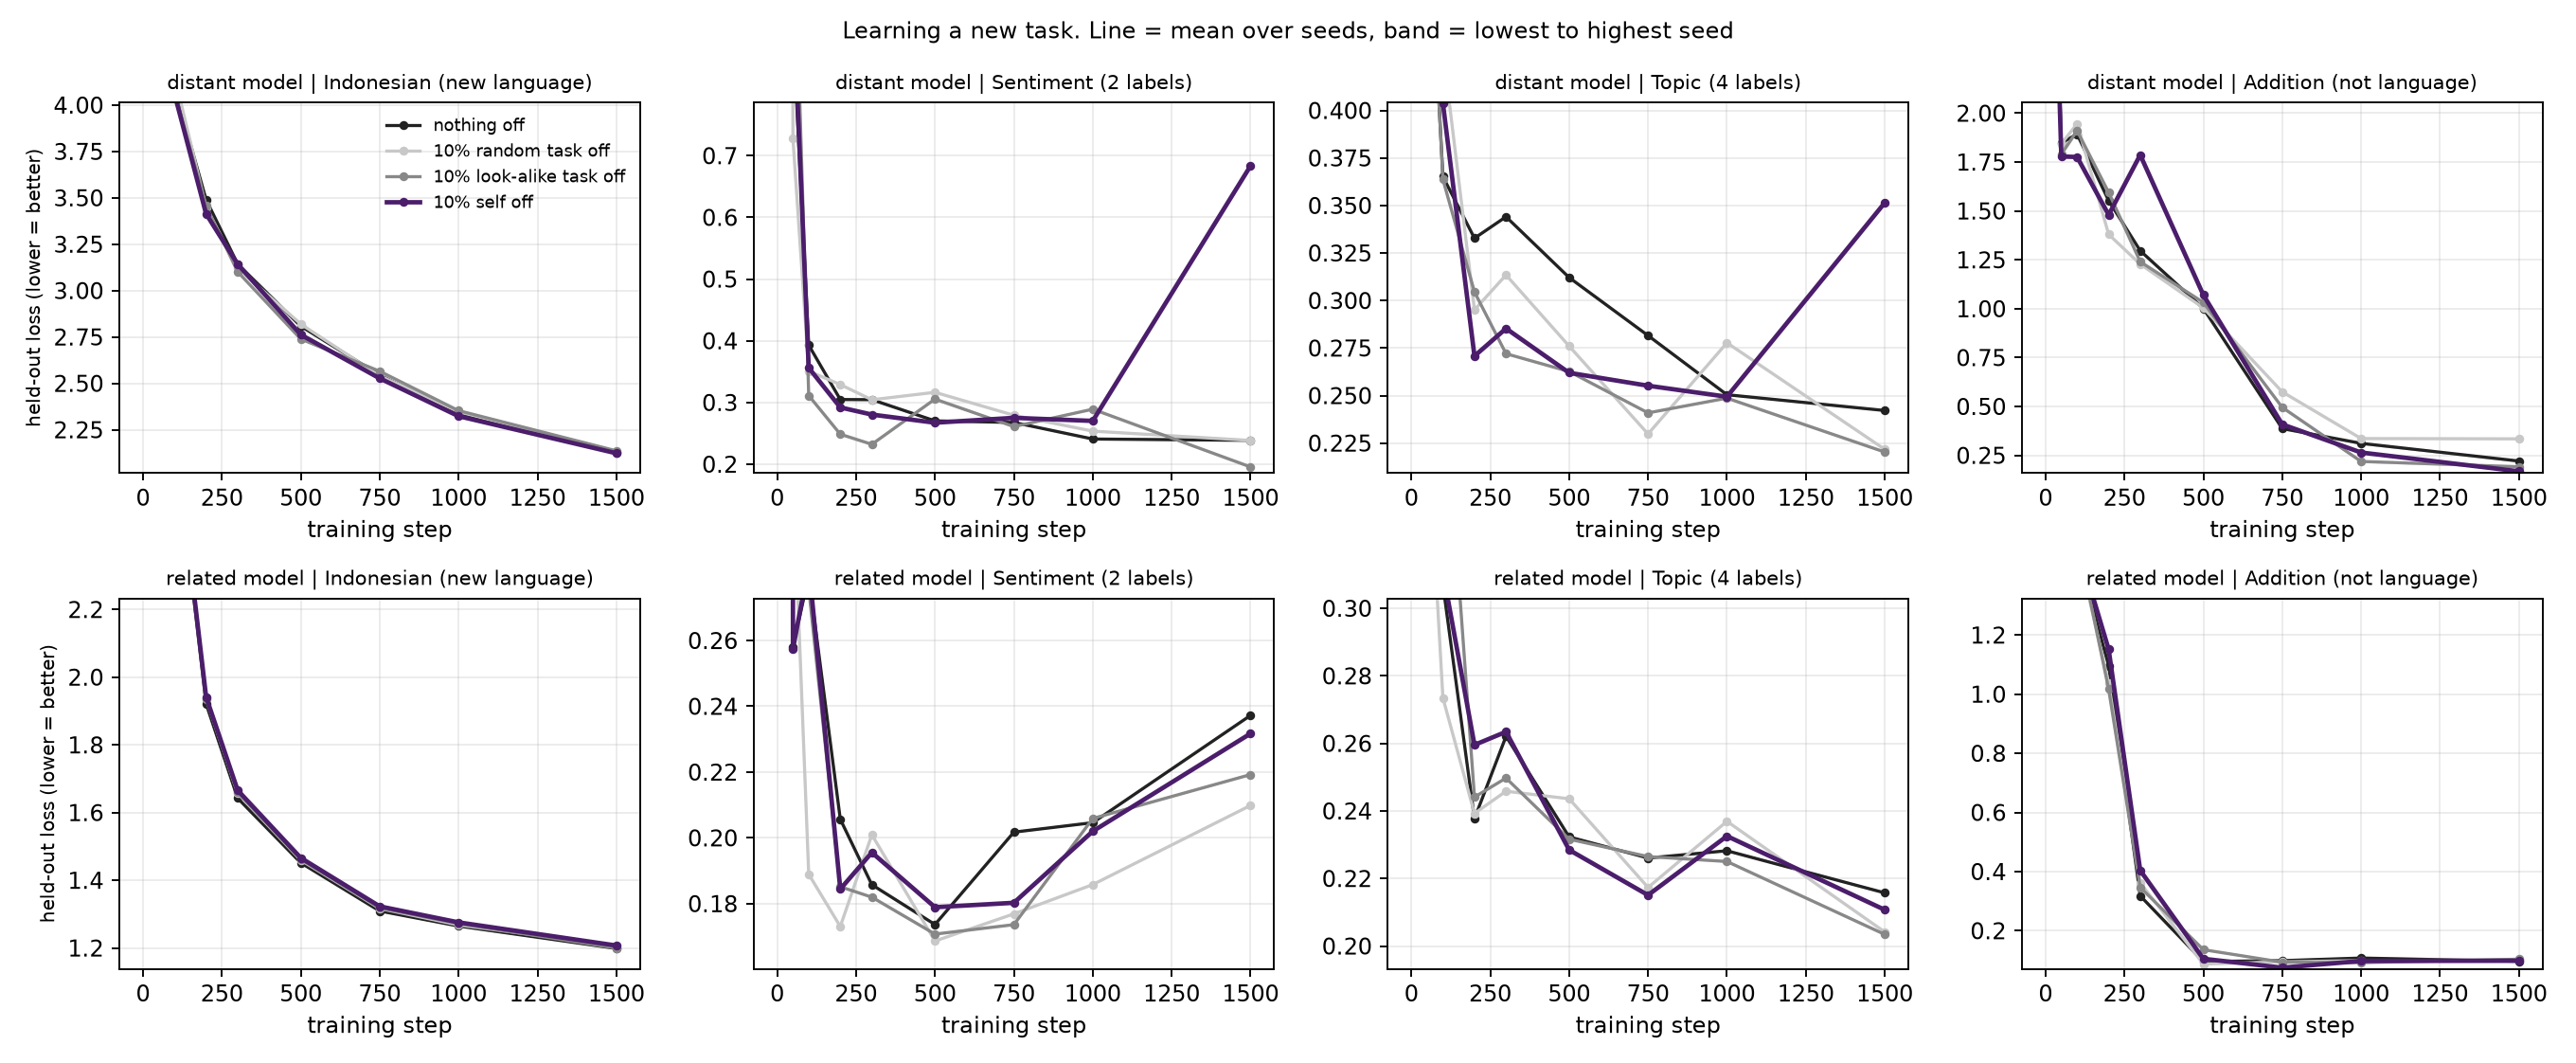

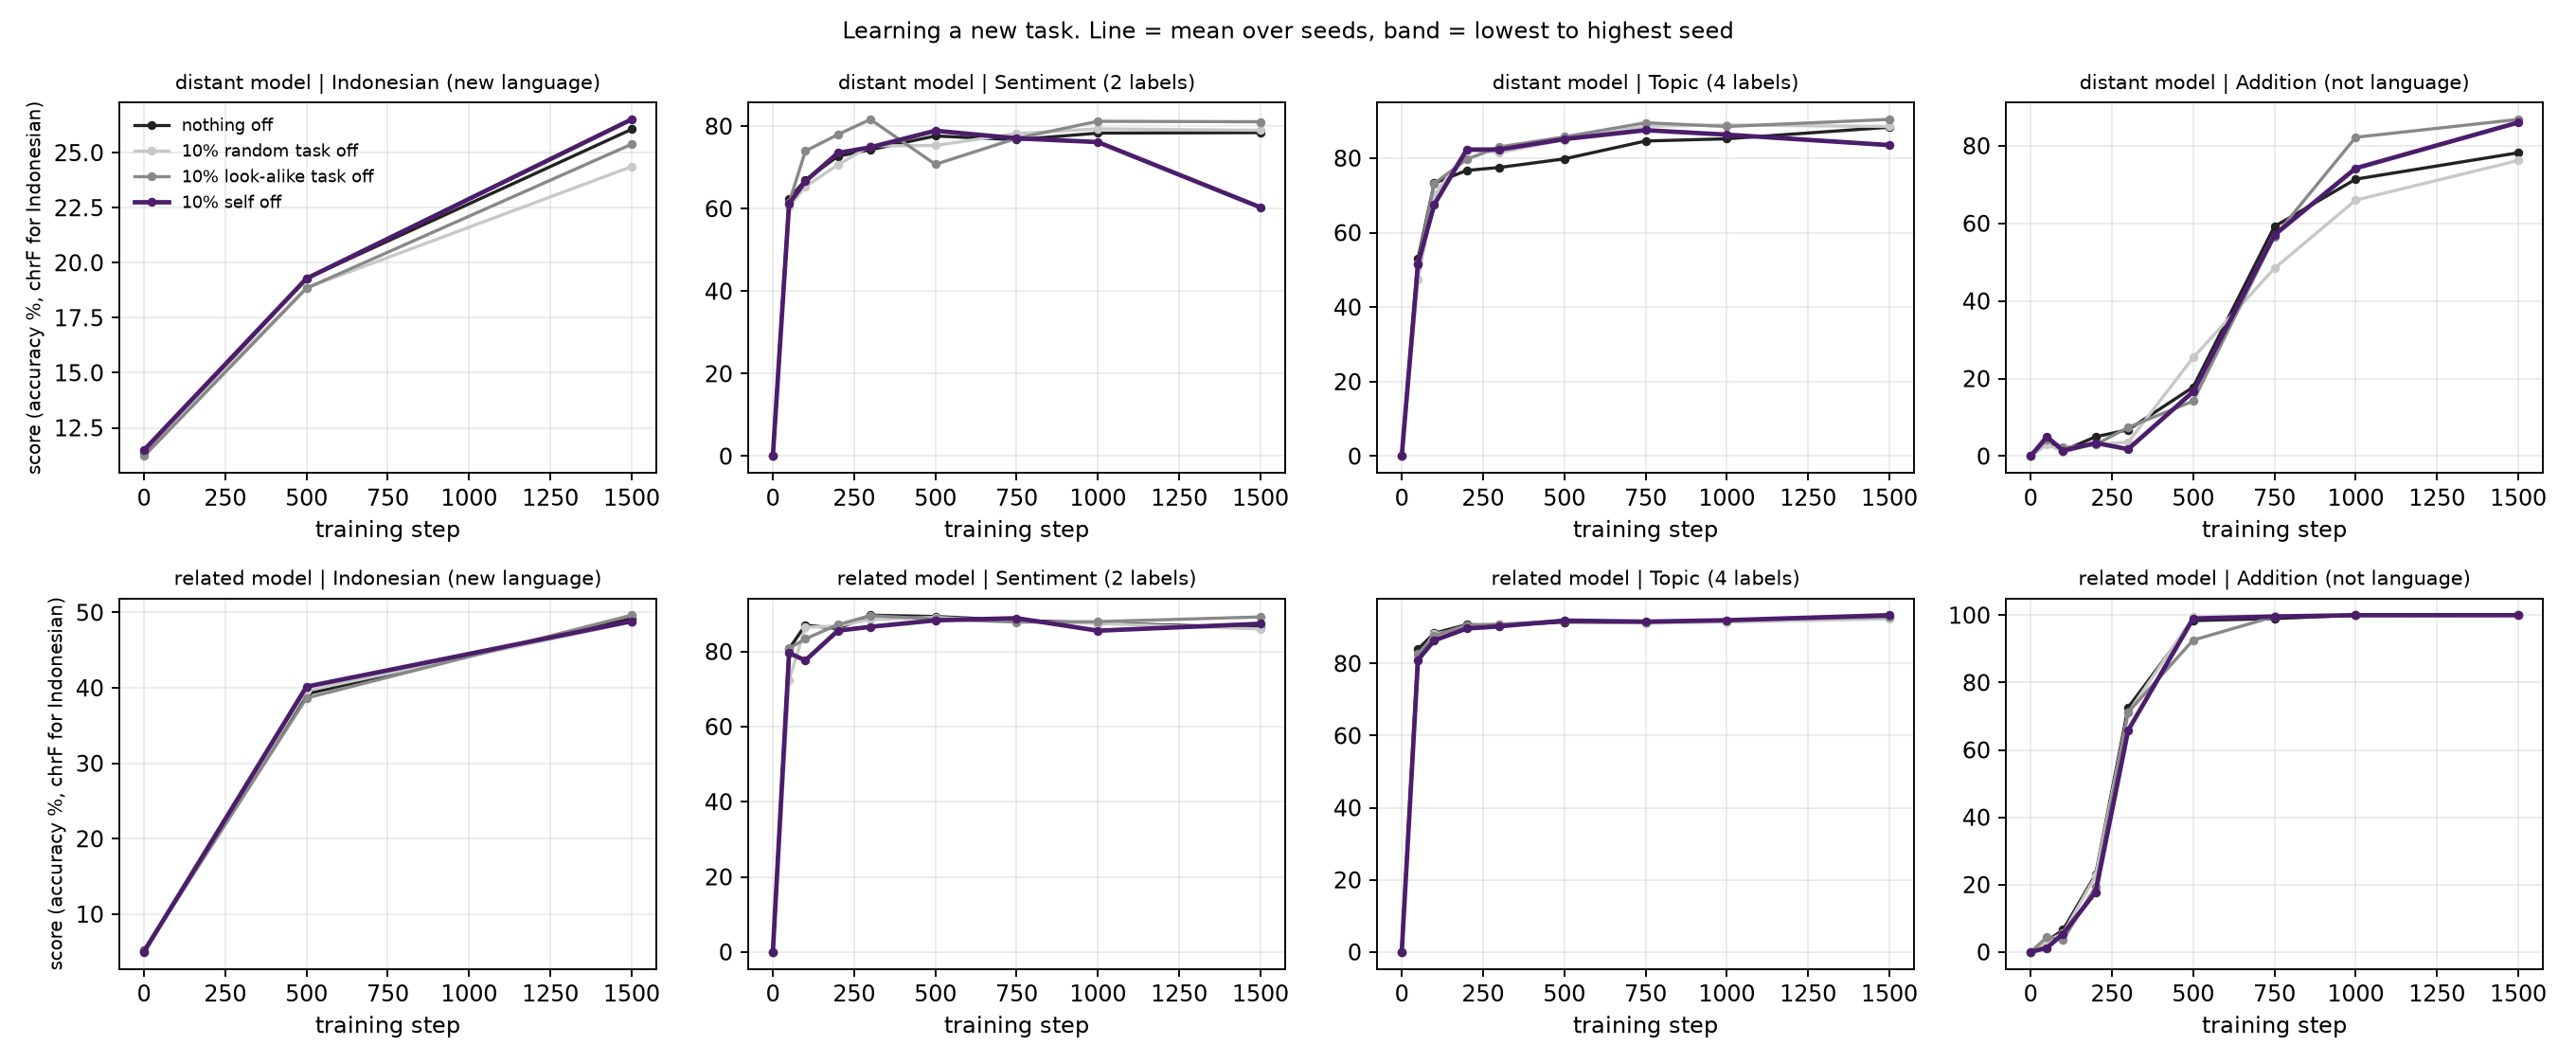

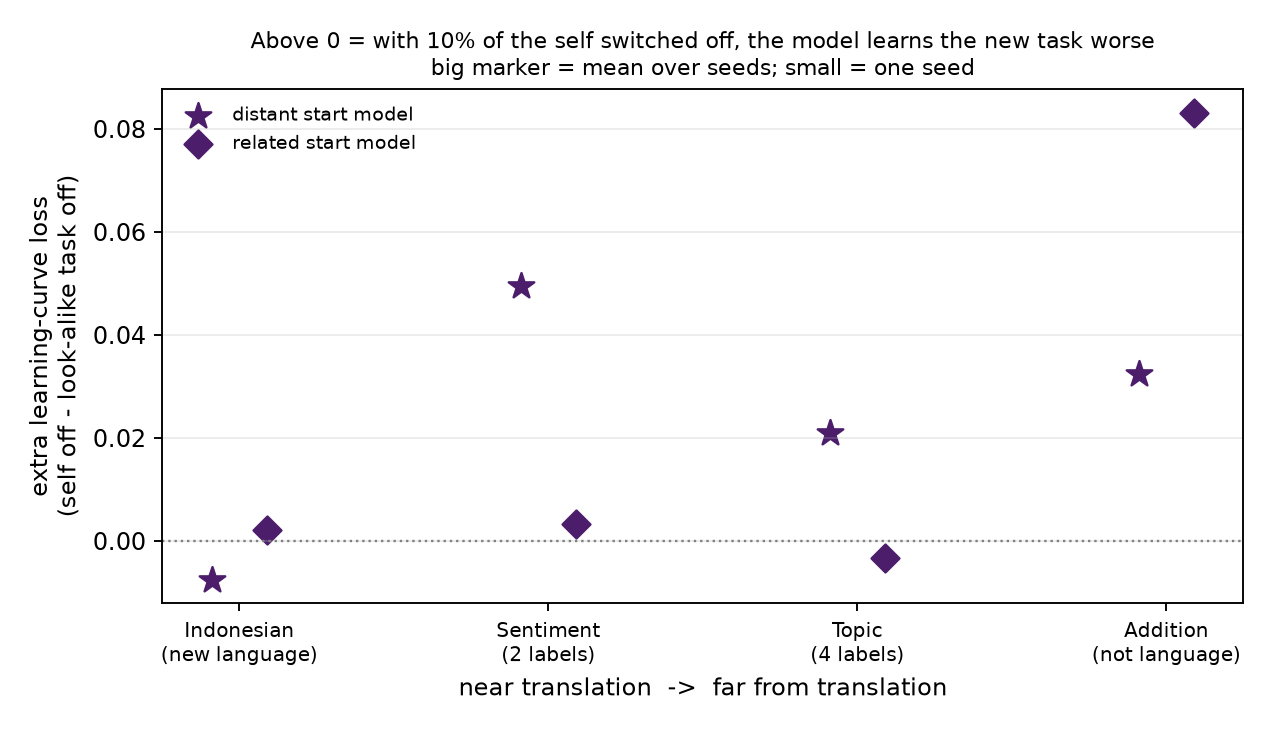

In [7]:
# look at seed 0 now (CPU only)
subprocess.run([sys.executable, "newtask_v9.py", "--summarize"])
for f in ["fig1_learning_curves_loss.png", "fig2_learning_curves_score.png", "fig3_near_to_far.png"]:
    display(Image(f"analysis/v9/newtask/{f}"))

In [8]:
# seeds 1 and 2
for s in ["1", "2"]:
    run("distant", "--start", f"distant={DIST}:{PD}", "--seeds", s)
    run("distant", "--start", "fresh", "--seeds", s)
    run("indic", "--start", f"related={REL}:{PR}", "--seeds", s)

start model: distant = v4b_continual_s0 phase 86 (last trained on zh) | language set distant: hi, zh, ar
  enc0.mlp: 2411 working neurons, self = 2270 (94%), switching off 241
  enc1.mlp: 2081 working neurons, self = 1942 (93%), switching off 208
  enc2.mlp: 2270 working neurons, self = 2115 (93%), switching off 227
  enc3.mlp: 2386 working neurons, self = 2235 (94%), switching off 239
  dec0.mlp: 2511 working neurons, self = 2388 (95%), switching off 251
  dec1.mlp: 2495 working neurons, self = 2340 (94%), switching off 250
  dec2.mlp: 2526 working neurons, self = 2249 (89%), switching off 253
  dec3.mlp: 2560 working neurons, self = 2468 (96%), switching off 256
  self found in 5s
  'next' task for this start model = ar (phase 87 of the normal schedule)
runs to do in this call: 16 (4 tasks x 4 conditions x seeds [1]; already done are skipped)
    enc0.mlp: self or task group too small, layer left intact
    enc1.mlp: self or task group too small, layer left intact
    enc2.mlp: self 

=== v9: learning a NEW task with part of the self switched off ===
one comparison = one start model x one seed x one task: self switched off vs look-alike task neurons switched off
learning slowness = average held-out loss over the learning curve (steps 50 ... end); lower = learned faster

AVERAGE OVER SEEDS (curve loss | final score; score = accuracy % or chrF for Indonesian)
                              curve_loss  final_score  seeds
task       start   cond                                     
addition   distant lookalike       1.040       83.067      3
                   none            1.108       77.267      3
                   random          1.067       79.067      3
                   self            1.092       85.933      3
           fresh   none            1.605       68.200      3
           related lookalike       0.646       99.867      3
                   none            0.638       99.800      3
                   random          0.629      100.000      3
          

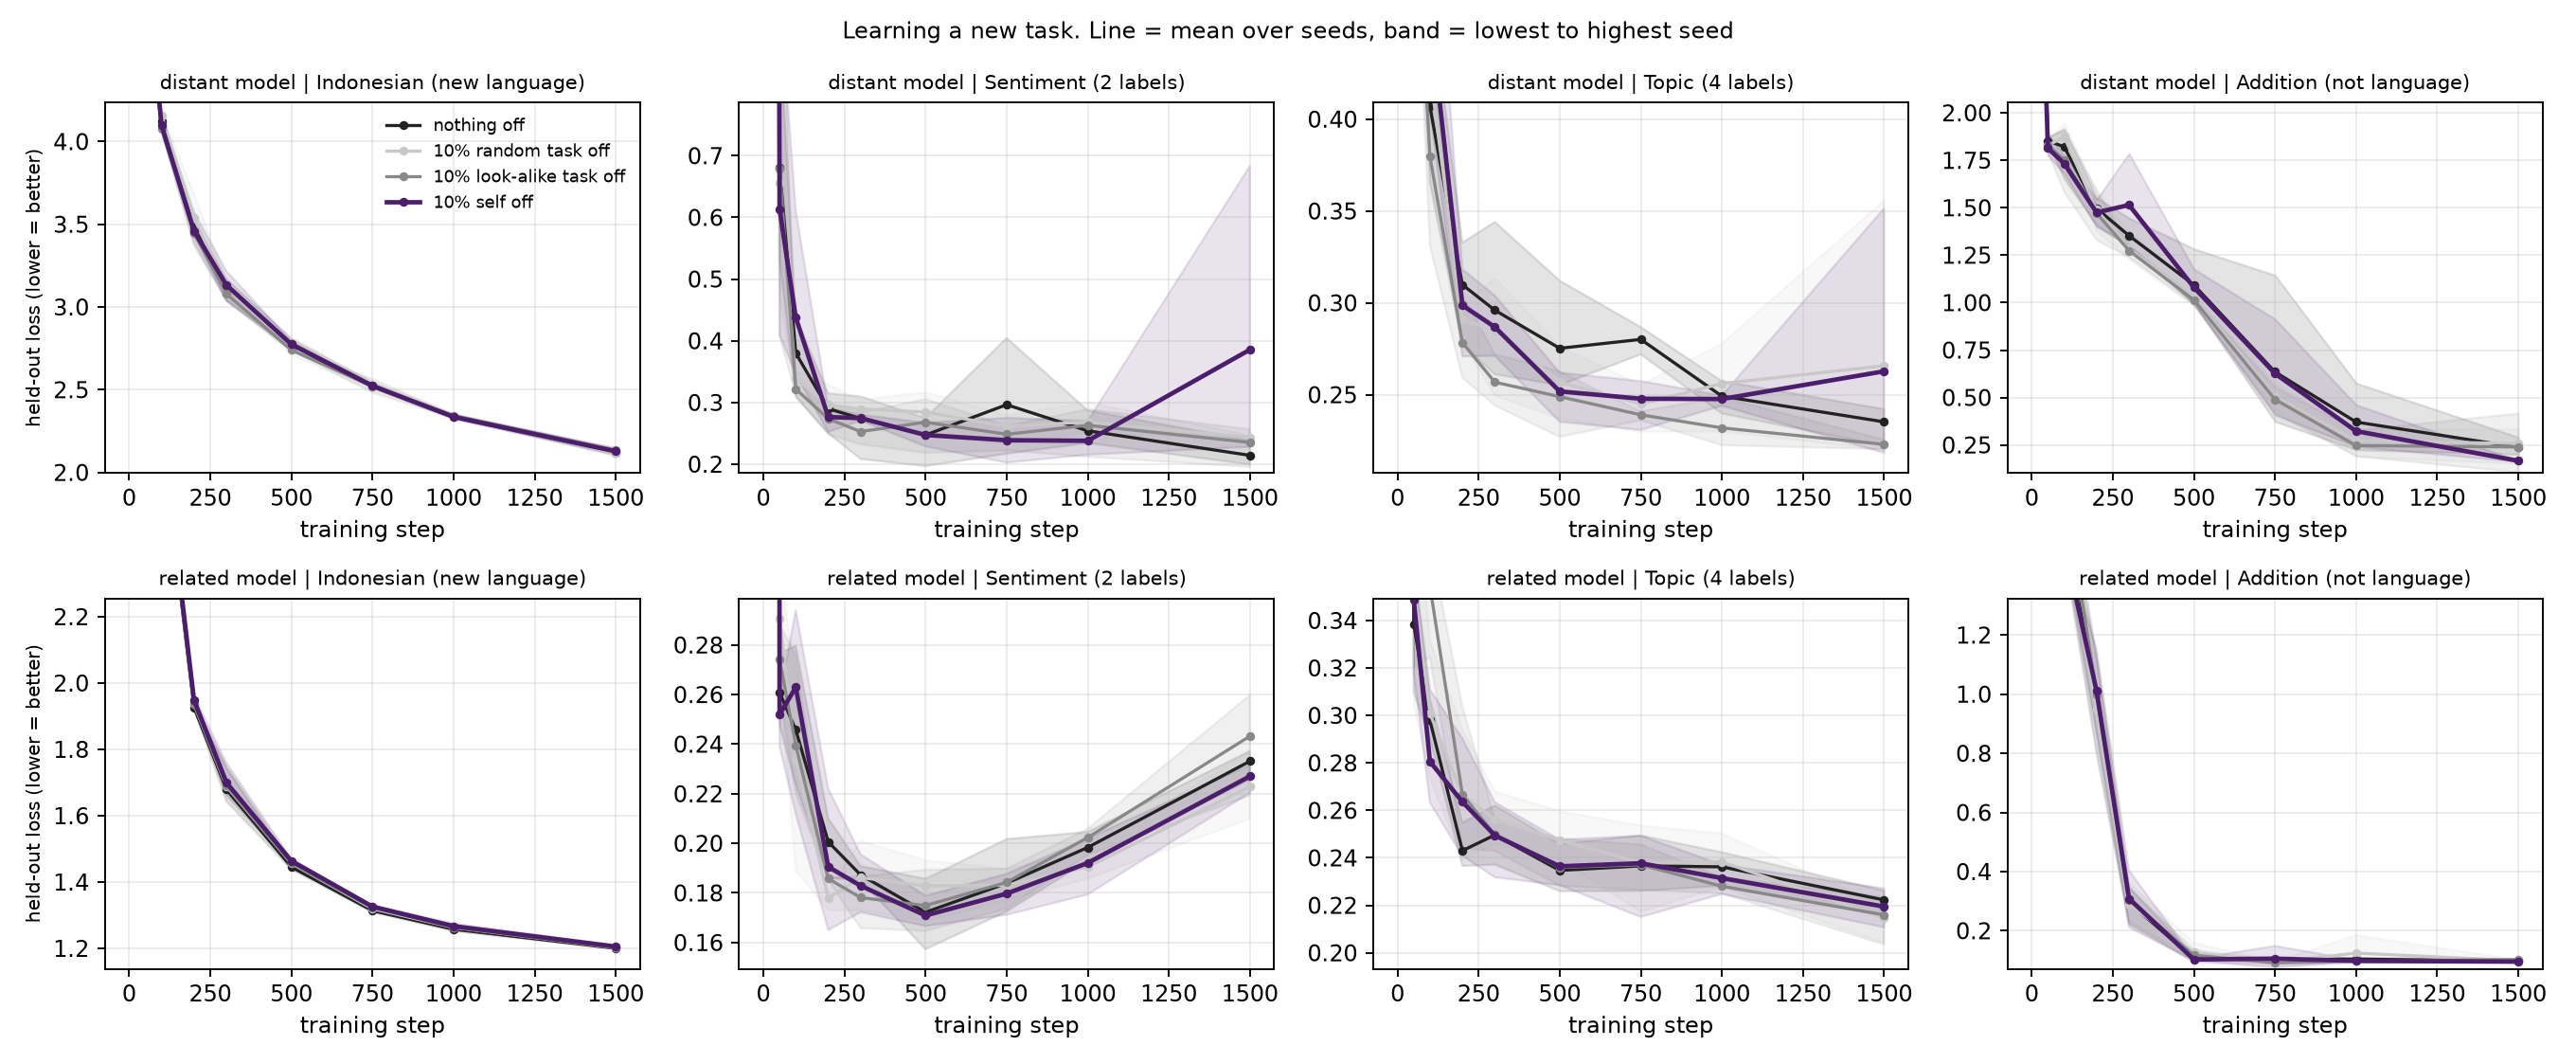

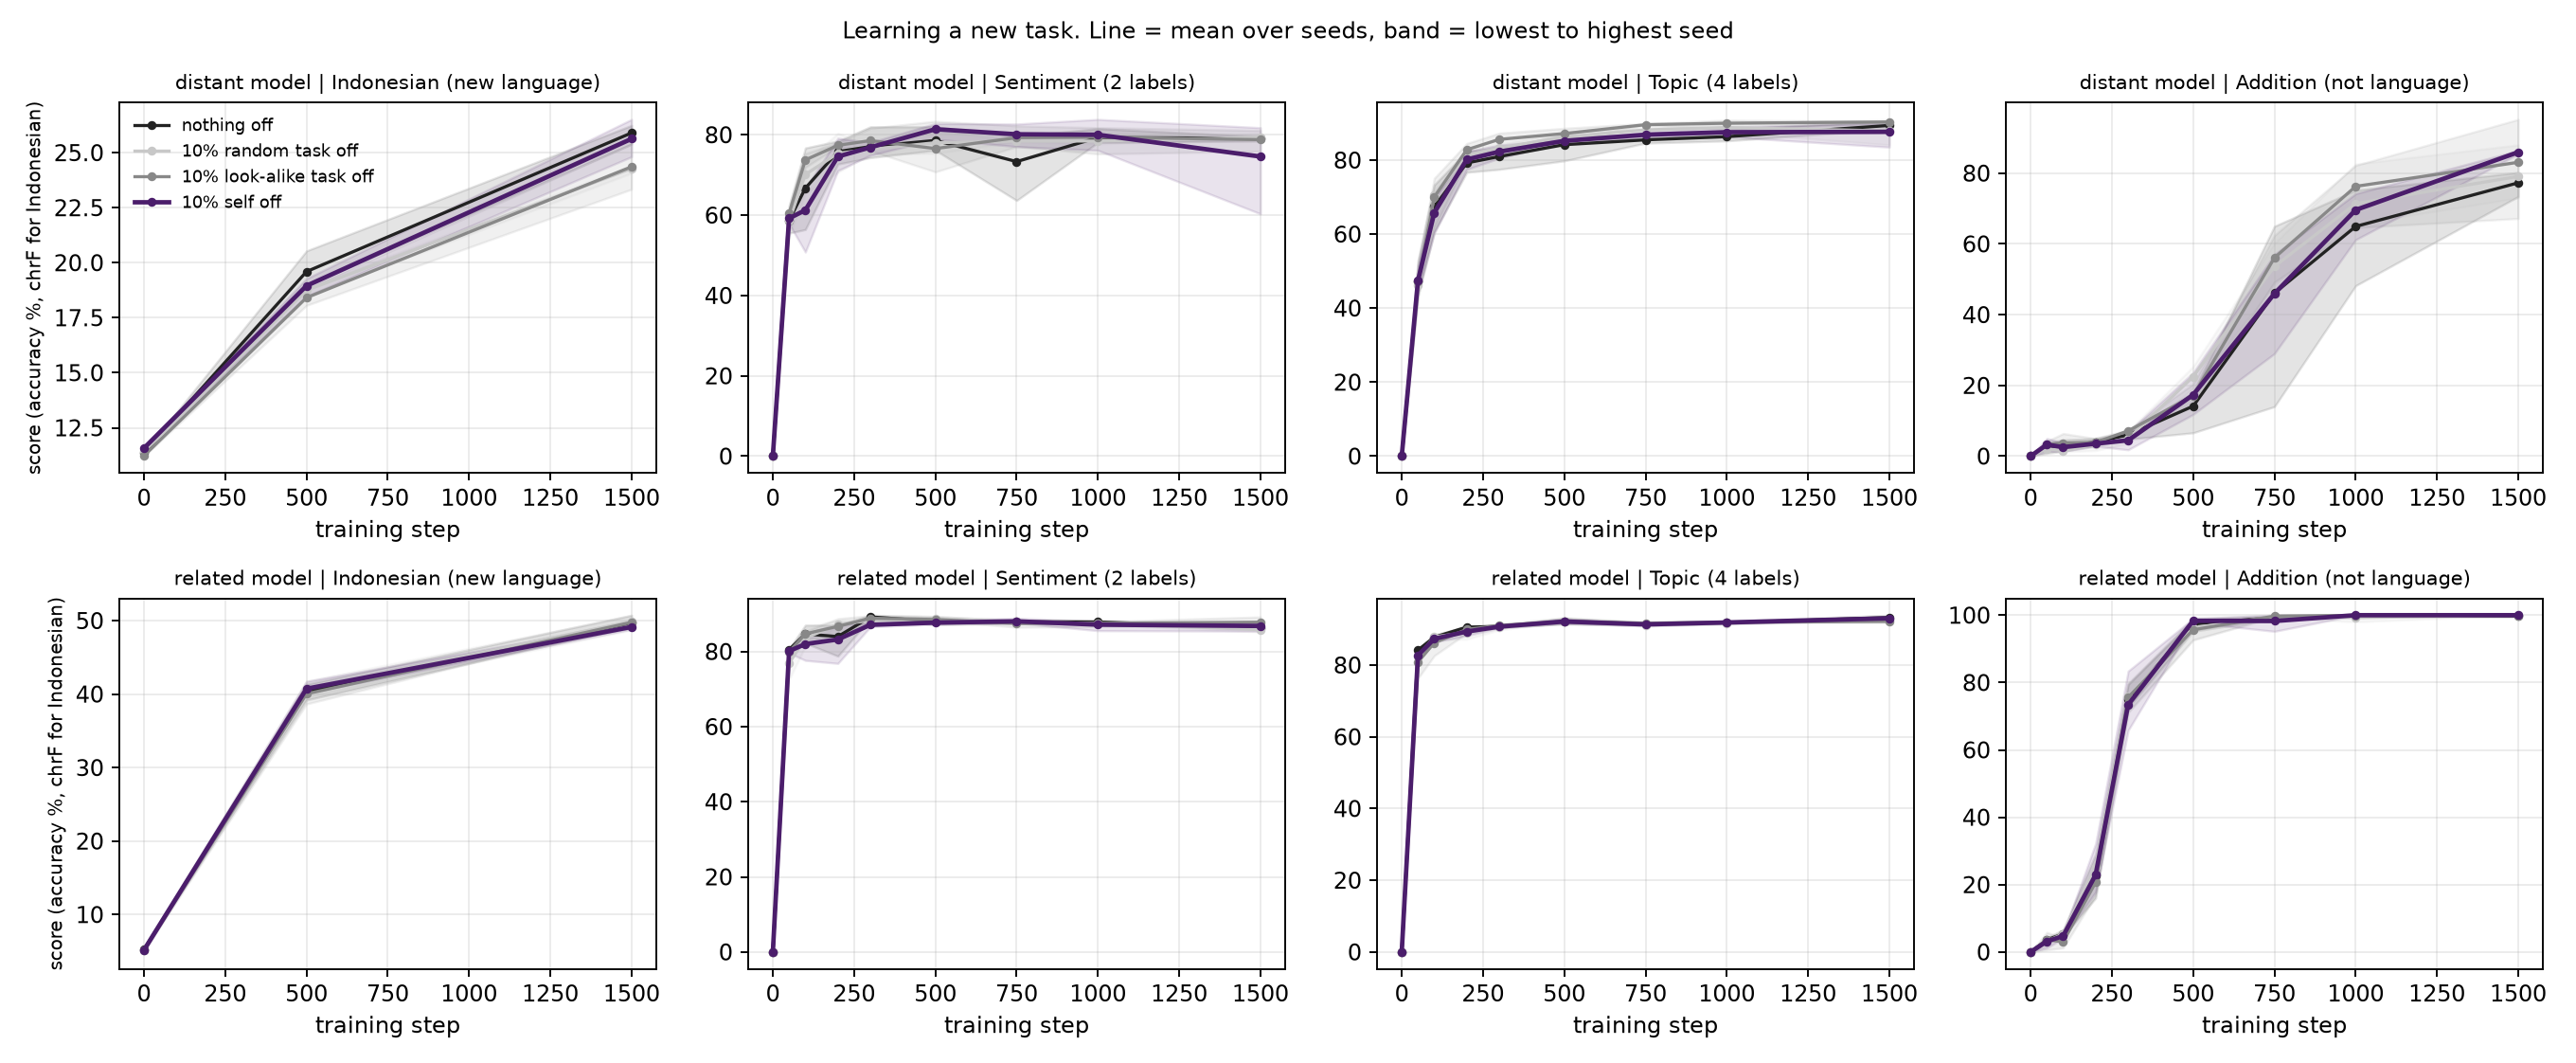

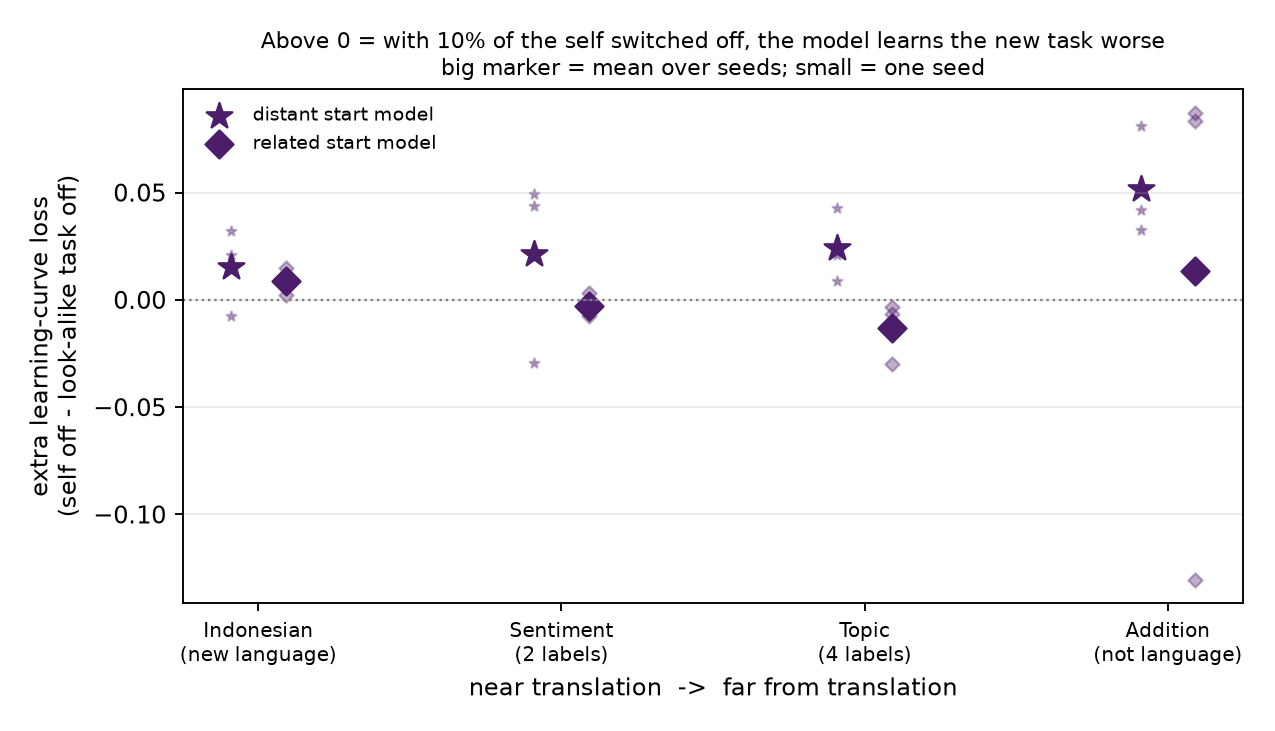

In [9]:
# final summary
subprocess.run([sys.executable, "newtask_v9.py", "--summarize"])
for f in ["fig1_learning_curves_loss.png", "fig2_learning_curves_score.png", "fig3_near_to_far.png"]:
    display(Image(f"analysis/v9/newtask/{f}"))